## 05 Model Evaluation

Notebook này đánh giá các mô hình đã huấn luyện ở notebook 04 trên tập test, là phần dữ liệu mô hình chưa từng thấy. Đầu vào là `data/processed/games_features.csv` và `models/mo_hinh.joblib`.

Tiêu chí thành công trong project charter là mô hình phải tốt hơn baseline trên tập test.

### 5.1. Đọc dữ liệu và mô hình

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score

sns.set_theme(style="whitegrid", palette="Set2")

data = pd.read_csv("../data/processed/games_features.csv", low_memory=False)
goi = joblib.load("../models/mo_hinh.joblib")

mo_hinh_hoi_quy = goi["hoi_quy"]
mo_hinh_phan_loai = goi["phan_loai"]
dac_trung_hoi_quy = goi["dac_trung_hoi_quy"]
dac_trung_phan_loai = goi["dac_trung_phan_loai"]

print("Số game:", len(data))
print(data["split"].value_counts())

Số game: 100025
split
train    80020
test     20005
Name: count, dtype: int64


### 5.2. Đánh giá mô hình hồi quy

Dùng R2 và MAE. MAE của mô hình A và C tính trên thang log, MAE của mô hình B tính bằng điểm phần trăm.

In [2]:
bo_du_lieu = {
    "A: Số đánh giá": (data, "log_reviews"),
    "B: Tỷ lệ tích cực": (data[data["Positive ratio"].notna()], "Positive ratio"),
    "C: Thời gian chơi": (data[data["Median playtime forever"] > 0], "log_playtime"),
}

ket_qua = []
for ten_muc_tieu, (du_lieu, muc_tieu) in bo_du_lieu.items():
    train = du_lieu[du_lieu["split"] == "train"]
    test = du_lieu[du_lieu["split"] == "test"]

    for ten_mo_hinh, mo_hinh in mo_hinh_hoi_quy[ten_muc_tieu].items():
        du_doan_train = mo_hinh.predict(train[dac_trung_hoi_quy])
        du_doan_test = mo_hinh.predict(test[dac_trung_hoi_quy])
        ket_qua.append({
            "Mục tiêu": ten_muc_tieu,
            "Mô hình": ten_mo_hinh,
            "R2 train": round(r2_score(train[muc_tieu], du_doan_train), 3),
            "R2 test": round(r2_score(test[muc_tieu], du_doan_test), 3),
            "MAE test": round(mean_absolute_error(test[muc_tieu], du_doan_test), 3),
        })

bang_hoi_quy = pd.DataFrame(ket_qua)
display(bang_hoi_quy)

,Mục tiêu,Mô hình,R2 train,R2 test,MAE test
0,A: Số đánh giá,Baseline,0.000,-0.000,1.926
1,A: Số đánh giá,Hồi quy tuyến tính,0.357,0.365,1.511
2,A: Số đánh giá,Random Forest,0.469,0.432,1.406
3,B: Tỷ lệ tích cực,Baseline,0.000,-0.000,14.229
4,B: Tỷ lệ tích cực,Hồi quy tuyến tính,0.132,0.134,13.046
5,B: Tỷ lệ tích cực,Random Forest,0.257,0.192,12.560
6,C: Thời gian chơi,Baseline,0.000,-0.000,1.101
7,C: Thời gian chơi,Hồi quy tuyến tính,0.122,0.138,1.023
8,C: Thời gian chơi,Random Forest,0.289,0.166,0.992


Nhận xét:

- Cả ba mục tiêu, mô hình đều tốt hơn baseline trên tập test, nên đạt tiêu chí trong project charter.
- Random Forest tốt nhất ở cả ba: R2 test 0,432, 0,192 và 0,166.
- Với tỷ lệ tích cực, MAE giảm từ 14,2 xuống 12,6 điểm. Mức giảm nhỏ, nghĩa là dự đoán đánh giá của một game từ các đặc điểm này chưa chính xác.
- Random Forest có R2 train cao hơn test khá nhiều ở mô hình C (0,289 và 0,166), đây là dấu hiệu overfitting. Hồi quy tuyến tính không có vấn đề này.

### 5.3. Kiểm tra phần dư của hồi quy tuyến tính

Phần dư là giá trị thực tế trừ giá trị dự đoán. Nếu mô hình phù hợp, phần dư phải phân bố đều quanh 0.

A: Số đánh giá - trung bình phần dư: 0.016 - độ lệch: 0.63
B: Tỷ lệ tích cực - trung bình phần dư: 0.247 - độ lệch: -0.94
C: Thời gian chơi - trung bình phần dư: -0.013 - độ lệch: -0.44


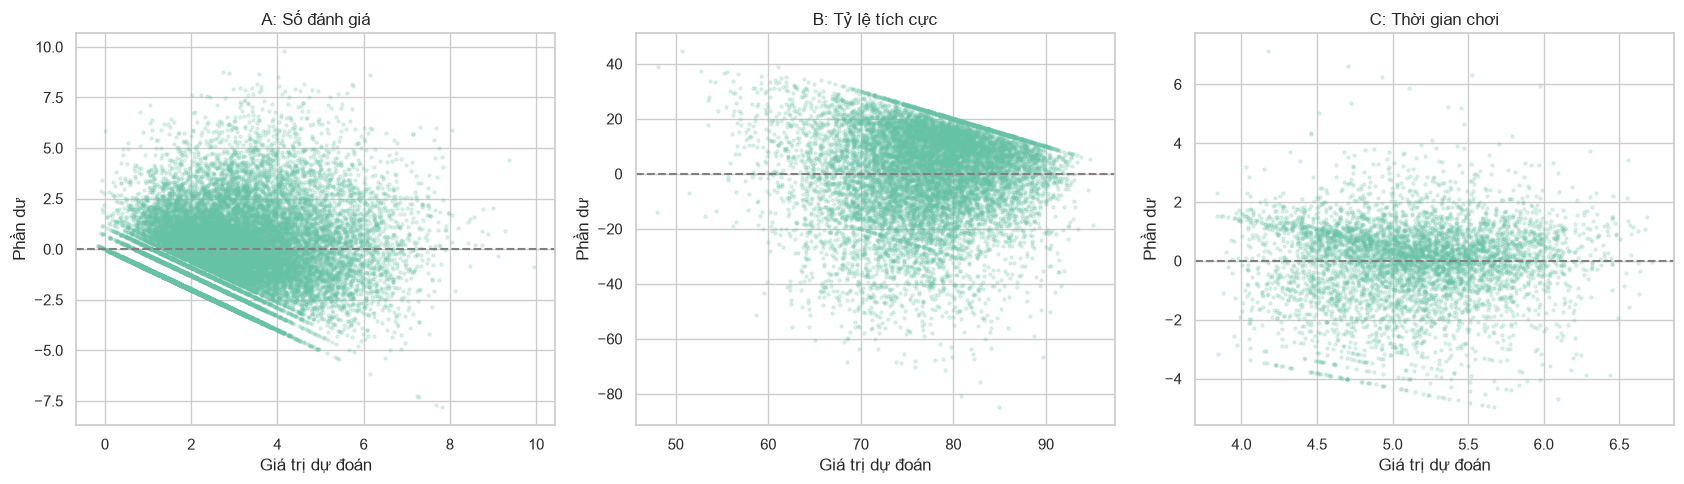

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

i = 0
for ten_muc_tieu, (du_lieu, muc_tieu) in bo_du_lieu.items():
    test = du_lieu[du_lieu["split"] == "test"]
    du_doan = mo_hinh_hoi_quy[ten_muc_tieu]["Hồi quy tuyến tính"].predict(test[dac_trung_hoi_quy])
    phan_du = test[muc_tieu] - du_doan

    axes[i].scatter(du_doan, phan_du, s=5, alpha=0.2)
    axes[i].axhline(0, color="gray", linestyle="--")
    axes[i].set(title=ten_muc_tieu, xlabel="Giá trị dự đoán", ylabel="Phần dư")
    print(ten_muc_tieu, "- trung bình phần dư:", round(phan_du.mean(), 3),
          "- độ lệch:", round(phan_du.skew(), 2))
    i = i + 1

plt.tight_layout()
plt.show()

Nhận xét:

- Trung bình phần dư gần 0 ở mô hình A và C. Mô hình B lệch nhẹ (0,247 điểm).
- Phần dư của mô hình B lệch trái (-0,94) vì tỷ lệ tích cực bị chặn ở 100%, nên có một đường chéo rõ trên biểu đồ. Đây là giới hạn của hồi quy tuyến tính với biến dạng tỷ lệ.
- Mô hình A có các đường chéo ở phía dưới vì nhiều game có rất ít đánh giá (0, 1, 2...), nên giá trị thực tế chỉ nhận vài mức.
- Vì vậy các hệ số nên xem là mức chênh lệch gần đúng.

### 5.4. Đánh giá mô hình phân loại

Accuracy dễ gây hiểu lầm khi dữ liệu lệch, vì baseline luôn đoán nhãn 0 vẫn có accuracy cao. Vì vậy xem thêm precision, recall, F1 và ROC-AUC.

In [4]:
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]
X_train = train[dac_trung_phan_loai]
y_train = train["has_ccu"]
X_test = test[dac_trung_phan_loai]
y_test = test["has_ccu"]

ket_qua = []
for ten, mo_hinh in mo_hinh_phan_loai.items():
    du_doan = mo_hinh.predict(X_test)
    xac_suat = mo_hinh.predict_proba(X_test)[:, 1]
    ket_qua.append({
        "Mô hình": ten,
        "Accuracy": round(accuracy_score(y_test, du_doan), 3),
        "Precision": round(precision_score(y_test, du_doan, zero_division=0), 3),
        "Recall": round(recall_score(y_test, du_doan), 3),
        "F1": round(f1_score(y_test, du_doan), 3),
        "ROC-AUC": round(roc_auc_score(y_test, xac_suat), 3),
        "F1 train": round(f1_score(y_train, mo_hinh.predict(X_train), zero_division=0), 3),
    })

bang_phan_loai = pd.DataFrame(ket_qua)
display(bang_phan_loai)

,Mô hình,Accuracy,Precision,Recall,F1,ROC-AUC,F1 train
0,Baseline,0.806,0.000,0.000,0.000,0.500,0.000
1,Logistic Regression,0.719,0.379,0.698,0.491,0.779,0.491
2,Random Forest,0.751,0.414,0.689,0.518,0.805,0.565


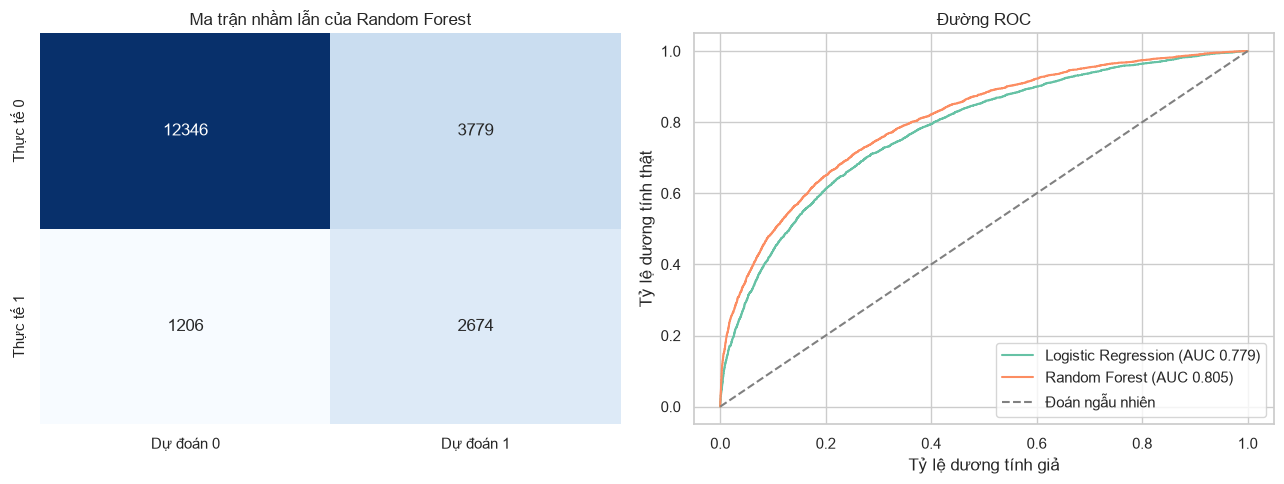

Ma trận nhầm lẫn:
[[12346  3779]
 [ 1206  2674]]


In [5]:
rung = mo_hinh_phan_loai["Random Forest"]
xac_suat_rung = rung.predict_proba(X_test)[:, 1]
du_doan_rung = rung.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ma_tran = confusion_matrix(y_test, du_doan_rung)
sns.heatmap(ma_tran, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Dự đoán 0", "Dự đoán 1"], yticklabels=["Thực tế 0", "Thực tế 1"])
axes[0].set_title("Ma trận nhầm lẫn của Random Forest")

for ten in ["Logistic Regression", "Random Forest"]:
    xac_suat = mo_hinh_phan_loai[ten].predict_proba(X_test)[:, 1]
    fpr, tpr, nguong = roc_curve(y_test, xac_suat)
    axes[1].plot(fpr, tpr, label=ten + " (AUC " + str(round(roc_auc_score(y_test, xac_suat), 3)) + ")")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Đoán ngẫu nhiên")
axes[1].set(title="Đường ROC", xlabel="Tỷ lệ dương tính giả", ylabel="Tỷ lệ dương tính thật")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Ma trận nhầm lẫn:")
print(ma_tran)

Nhận xét:

- Baseline có accuracy cao nhất (0,806) dù không phát hiện được game nào có Peak CCU > 0. Đây là lý do không dùng accuracy một mình.
- Random Forest tốt hơn baseline và Logistic Regression ở F1 (0,518) và ROC-AUC (0,805).
- Random Forest phát hiện được 2.674 trong 3.880 game có Peak CCU > 0 (recall 0,689), nhưng cũng báo nhầm 3.779 game. Precision chỉ 0,414.

### 5.5. Chọn ngưỡng phân loại

Mặc định mô hình chọn nhãn 1 khi xác suất từ 0,5. Thay đổi ngưỡng sẽ đổi giữa precision và recall.

In [6]:
ket_qua = []
for nguong in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    du_doan = (xac_suat_rung >= nguong).astype(int)
    ket_qua.append({
        "Ngưỡng": nguong,
        "Precision": round(precision_score(y_test, du_doan, zero_division=0), 3),
        "Recall": round(recall_score(y_test, du_doan), 3),
        "F1": round(f1_score(y_test, du_doan), 3),
    })
bang_nguong = pd.DataFrame(ket_qua)
display(bang_nguong)

,Ngưỡng,Precision,Recall,F1
0,0.3,0.281,0.904,0.428
1,0.4,0.346,0.802,0.483
2,0.5,0.414,0.689,0.518
3,0.6,0.501,0.549,0.524
4,0.7,0.614,0.386,0.474
5,0.8,0.774,0.219,0.341


Nhận xét:

- F1 cao nhất ở ngưỡng 0,6 (0,524), gần bằng ngưỡng 0,5 (0,518).
- Nếu muốn không bỏ sót game có Peak CCU > 0 thì dùng ngưỡng thấp: ngưỡng 0,3 có recall 0,904 nhưng precision chỉ 0,281.
- Nếu muốn dự đoán chắc chắn hơn thì dùng ngưỡng cao: ngưỡng 0,8 có precision 0,774 nhưng recall còn 0,219.

### 5.6. Kiểm định chéo (cross-validation)

Chia tập train thành 5 phần, lần lượt lấy mỗi phần làm tập kiểm tra. Nếu điểm giữa các lần gần nhau thì kết quả ổn định, không phụ thuộc vào một lần chia may mắn.

In [7]:
chia_5_phan = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for ten in ["Logistic Regression", "Random Forest"]:
    diem = cross_val_score(mo_hinh_phan_loai[ten], X_train, y_train, cv=chia_5_phan, scoring="f1", n_jobs=-1)
    print(ten, "- F1 từng lần:", diem.round(3), "- trung bình:", round(diem.mean(), 3),
          "- độ lệch chuẩn:", round(diem.std(), 4))

Logistic Regression - F1 từng lần: [0.493 0.491 0.49  0.492 0.489] - trung bình: 0.491 - độ lệch chuẩn: 0.0014


Random Forest - F1 từng lần: [0.518 0.525 0.522 0.521 0.52 ] - trung bình: 0.521 - độ lệch chuẩn: 0.0022


Nhận xét: F1 trung bình của Random Forest là 0,521 và của Logistic Regression là 0,491, độ lệch chuẩn rất nhỏ, gần bằng kết quả trên tập test. Vậy kết quả ổn định, không phải do một lần chia may mắn.

### 5.7. Đặc trưng quan trọng

Dùng permutation importance: xáo trộn một cột trên tập test rồi xem ROC-AUC giảm bao nhiêu. Giảm càng nhiều thì cột đó càng quan trọng.

,Đặc trưng,Mức giảm ROC-AUC
3,log_achievements,0.0423
4,Năm phát hành,0.0419
20,cat_Steam Cloud,0.0404
0,log_price,0.0332
6,genre_Indie,0.0105
10,genre_Simulation,0.0093
8,genre_Action,0.0078
17,cat_Multi-player,0.0049
2,has_achievements,0.0048
1,is_free,0.0036


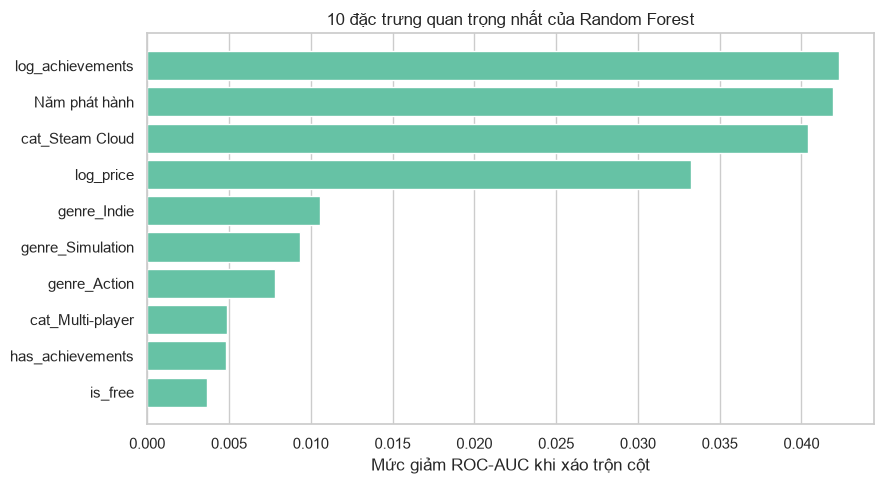

In [8]:
quan_trong = permutation_importance(rung, X_test, y_test, scoring="roc_auc",
                                    n_repeats=5, random_state=42, n_jobs=-1)

bang_quan_trong = pd.DataFrame({
    "Đặc trưng": dac_trung_phan_loai,
    "Mức giảm ROC-AUC": quan_trong.importances_mean,
}).sort_values("Mức giảm ROC-AUC", ascending=False).head(10)
display(bang_quan_trong.round(4))

plt.figure(figsize=(9, 5))
ax = plt.gca()
ax.barh(bang_quan_trong["Đặc trưng"], bang_quan_trong["Mức giảm ROC-AUC"])
ax.invert_yaxis()
ax.set(title="10 đặc trưng quan trọng nhất của Random Forest", xlabel="Mức giảm ROC-AUC khi xáo trộn cột")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Nhận xét:

- Bốn đặc trưng quan trọng nhất là số Achievements, năm phát hành, Steam Cloud và giá. Thể loại ít quan trọng hơn.
- Độ quan trọng cho biết mô hình dựa vào cột nào để dự đoán, không có nghĩa thêm Steam Cloud sẽ làm game đông người chơi hơn. Các tính năng này có thể chỉ phản ánh game được đầu tư nhiều hơn.

Kết luận:

- Các mô hình tốt hơn baseline và kết quả ổn định, nhưng khả năng dự đoán ở mức vừa phải.
- Mô hình chỉ dùng thông tin có trước khi phát hành, nên không thể biết chất lượng thật hay ngân sách quảng bá. Đây là lý do R2 và precision không cao.
- Dự án tập trung vào mối liên hệ nên mô hình chủ yếu để hỗ trợ trả lời RQ, chưa đủ tốt để dự đoán cho từng game.

#### Lưu bảng kết quả

In [9]:
# Lưu các bảng chính để dùng trong báo cáo
bang_hoi_quy.to_csv("../reports/tables/ket_qua_hoi_quy.csv", encoding="utf-8-sig")
bang_phan_loai.to_csv("../reports/tables/ket_qua_phan_loai.csv", encoding="utf-8-sig")
bang_nguong.to_csv("../reports/tables/chon_nguong.csv", encoding="utf-8-sig")
print("Đã lưu bảng vào reports/tables")

Đã lưu bảng vào reports/tables
